# Follower (hydrostatic) pressure

This example shows how a follower pressure enters the linear buckling, non-linear static, linear static and vibration analyses of `panels`. The buckling pressures of rings are checked against closed-form solutions, and those of sandwich cylinders against Han et al. (2004).

A pressure added with `follower=True` in `Shell.add_pressure_load` stays normal to the deformed mid-surface and acts on its deformed area, like the pressure of a fluid. In the undeformed state it equals the dead load returned by `Shell.calc_fext`. The part of its force vector that depends on the configuration enters `Shell.calc_fint`. Its load stiffness `Shell.calc_kCfollower`, the derivative of that part, is unsymmetric in general and enters `Shell.calc_kT`, both at the load factor `inc`. The theory, the truncation of the area vector and the conditions for a symmetric load stiffness (Hibbitt, 1979; Schweizerhof and Ramm, 1984) are derived in [Follower pressure loads: theory](../follower_pressure.rst).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import Analysis, freq, lb, solve, static
from panels.shell import Shell

# closed-form solutions and data of the literature, shared with the tests
import follower_utils
val = follower_utils.val


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val_, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val_, ref, (val_ - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## Linear buckling of rings and long cylinders

The pre-buckling state is the linear static solution $\boldsymbol{c}_0$ under a unit external pressure. The buckling problem of a follower pressure adds the load stiffness to the geometric stiffness:

$$
\left(\boldsymbol{K}_C + \lambda \left(\boldsymbol{K}_G(\boldsymbol{c}_0) + \boldsymbol{K}_{C,follower}\right)\right)\boldsymbol{c} = \boldsymbol{0},
$$

solved with `structsolve.lb`, which uses the solvers of unsymmetric matrices when needed.

A long cylinder buckles as a ring. It is modelled with a quarter of the circumference, $b = \pi r/2$, and symmetry planes. The ends $x = 0, a$ are in generalized plane strain: $u$ and the slopes $v_{,x}$, $w_{,x}$ are constrained, and so is the rotation $\phi_x$ of the shear deformation theories. The straight edges are symmetry planes of the modes $\cos(n y/r)$ with $n$ even: $v$, $w_{,y}$ and $\phi_y$ are constrained.

In [2]:
def ring_shell(model, R, stack, plyts, laminaprops, m=4, n=15, **kwargs):
    s = Shell(model=model, **kwargs)
    s.r = R
    s.a = 0.5*R
    s.b = np.pi/2*R
    s.stack = list(stack)
    s.plyts = list(plyts)
    s.laminaprops = list(laminaprops)
    s.m = m
    s.n = n
    for e in ('x1', 'x2', 'y1', 'y2'):
        for f in 'uvw':
            setattr(s, e + f, 1.)
            setattr(s, e + f + 'r', 1.)
    s.x1u = s.x2u = 0.
    s.x1vr = s.x2vr = 0.
    s.x1wr = s.x2wr = 0.
    s.y1v = s.y2v = 0.
    s.y1wr = s.y2wr = 0.
    s.x1phiy = s.x2phiy = 1.
    s.x1phix = s.x2phix = 0.
    s.y1phix = s.y2phix = 1.
    s.y1phiy = s.y2phiy = 0.
    return s


def ring_buckling_pressure(s, load='follower', zp=0.):
    """Critical external pressure and mode of a dead, follower or centrally
    directed pressure"""
    s.clear_loads()
    s.add_pressure_load(-1., cte=False, follower=(load == 'follower'), zp=zp)
    k0 = s.calc_kC()
    c0 = solve(k0, s.calc_fext(), silent=True)
    K = s.calc_kG(c=c0)
    if load == 'follower':
        K = K + s.calc_kCfollower()
    elif load == 'central':
        # no kernel in panels: load stiffness integrated independently
        K = K + val.central_load_stiffness(s, -1.*(1 + zp/s.r))
    eigvals, eigvecs = lb(k0, K, silent=True, num_eigvalues=4)
    return np.real(eigvals[0]), np.real(eigvecs[:, 0])

### Isotropic ring: three kinds of pressure

The ring has $r = 1$ m and $h = 0.01$ m, and is made of aluminium, $E = 70$ GPa, $\nu = 0.3$. The FSDT models use the shear correction factor 5/6. For the ring mode $n$, the second variation of the total potential energy reduces to a small eigenvalue problem in the amplitudes of $w$, $v$ and of the rotation. Its smallest root is the closed form of the same discrete theory, `ring_closed_form` of `tests/tests_shell/test_follower_pressure_validation.py`, which panels must reproduce to the discretization error.

In the inextensional limit, $p_{cr} r^3/D$ is 3 for the follower pressure, 4 for the dead load (constant direction) and 4.5 for the centrally directed pressure with Sanders' kinematics. These are the classical values (Timoshenko and Gere, 1961; Brush and Almroth, 1975), the critical loads $3EI/r^3$, $4EI/r^3$ and $4.5EI/r^3$ of a ring of Pflüger (1975), p. 403. Donnell's kinematics neglect $v/r$ in the rotation and give 16/5, 4 and 64/15. With $r/h = 100$, the extensibility and the transverse shear change these values by about $(h/r)^2$.

In [3]:
INEXTENSIONAL = {('sanders', 'follower'): 3., ('sanders', 'dead'): 4.,
                 ('sanders', 'central'): 4.5, ('donnell', 'follower'): 16/5,
                 ('donnell', 'dead'): 4., ('donnell', 'central'): 64/15}
rows = []
for model in ['cylshell_clpt_sanders', 'cylshell_clpt_donnell',
              'cylshell_fsdt_sanders', 'cylshell_fsdt_donnell']:
    kin = 'sanders' if 'sanders' in model else 'donnell'
    for load in ['follower', 'dead', 'central']:
        s = ring_shell(model, 1., [0.], [0.01], [val.ISO],
                       fsdt_shear_correction=5/6)
        p_cr, mode = ring_buckling_pressure(s, load)
        A22, D22 = s.ABD[1, 1], s.ABD[4, 4]
        S = s.ABD[6, 6] if 'fsdt' in model else None
        closed = -val.ring_closed_form(kin, load, 2, A22, D22, s.r, S)
        print('%-22s %-8s p_cr = %.6f Pa, p_cr r^3/D = %.5f'
              % (model, load, p_cr, p_cr*s.r**3/D22))
        rows.append(('`%s`, %s, $p_{cr}$ (Pa)' % (model, load), p_cr, closed,
                     'closed form of the discrete theory, mode $n = 2$'))
        rows.append(('`%s`, %s, $p_{cr} r^3/D$' % (model, load),
                     p_cr*s.r**3/D22, INEXTENSIONAL[(kin, load)],
                     'inextensional limit'))
        if (model, load) == ('cylshell_clpt_sanders', 'follower'):
            ring_mode = (s, mode)
results_table(rows)

cylshell_clpt_sanders  follower p_cr = 19230.608976 Pa, p_cr r^3/D = 2.99998
cylshell_clpt_sanders  dead     p_cr = 25641.025642 Pa, p_cr r^3/D = 4.00000
cylshell_clpt_sanders  central  p_cr = 28846.093752 Pa, p_cr r^3/D = 4.49999
cylshell_clpt_donnell  follower p_cr = 20512.711112 Pa, p_cr r^3/D = 3.19998
cylshell_clpt_donnell  dead     p_cr = 25641.025641 Pa, p_cr r^3/D = 4.00000


cylshell_clpt_donnell  central  p_cr = 27350.411143 Pa, p_cr r^3/D = 4.26666
cylshell_fsdt_sanders  follower p_cr = 19228.411461 Pa, p_cr r^3/D = 2.99963
cylshell_fsdt_sanders  dead     p_cr = 25638.095571 Pa, p_cr r^3/D = 3.99954


cylshell_fsdt_sanders  central  p_cr = 28842.797437 Pa, p_cr r^3/D = 4.49948
cylshell_fsdt_donnell  follower p_cr = 20510.367082 Pa, p_cr r^3/D = 3.19962
cylshell_fsdt_donnell  dead     p_cr = 25638.095572 Pa, p_cr r^3/D = 3.99954


cylshell_fsdt_donnell  central  p_cr = 27347.285740 Pa, p_cr r^3/D = 4.26618


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `cylshell_clpt_sanders`, follower, $p_{cr}$ (Pa) | 19230.6 | 19230.6 | +6.60e-12 | closed form of the discrete theory, mode $n = 2$ |
| `cylshell_clpt_sanders`, follower, $p_{cr} r^3/D$ | 2.99998 | 3 | -8.33e-06 | inextensional limit |
| `cylshell_clpt_sanders`, dead, $p_{cr}$ (Pa) | 25641 | 25641 | +2.75e-11 | closed form of the discrete theory, mode $n = 2$ |
| `cylshell_clpt_sanders`, dead, $p_{cr} r^3/D$ | 4 | 4 | +2.56e-11 | inextensional limit |
| `cylshell_clpt_sanders`, central, $p_{cr}$ (Pa) | 28846.1 | 28846.1 | +2.34e-11 | closed form of the discrete theory, mode $n = 2$ |
| `cylshell_clpt_sanders`, central, $p_{cr} r^3/D$ | 4.49999 | 4.5 | -2.08e-06 | inextensional limit |
| `cylshell_clpt_donnell`, follower, $p_{cr}$ (Pa) | 20512.7 | 20512.7 | -2.97e-12 | closed form of the discrete theory, mode $n = 2$ |
| `cylshell_clpt_donnell`, follower, $p_{cr} r^3/D$ | 3.19998 | 3.2 | -5.33e-06 | inextensional limit |
| `cylshell_clpt_donnell`, dead, $p_{cr}$ (Pa) | 25641 | 25641 | +7.46e-12 | closed form of the discrete theory, mode $n = 2$ |
| `cylshell_clpt_donnell`, dead, $p_{cr} r^3/D$ | 4 | 4 | +6.83e-12 | inextensional limit |
| `cylshell_clpt_donnell`, central, $p_{cr}$ (Pa) | 27350.4 | 27350.4 | +7.77e-12 | closed form of the discrete theory, mode $n = 2$ |
| `cylshell_clpt_donnell`, central, $p_{cr} r^3/D$ | 4.26666 | 4.26667 | -5.93e-07 | inextensional limit |
| `cylshell_fsdt_sanders`, follower, $p_{cr}$ (Pa) | 19228.4 | 19228.4 | -1.08e-11 | closed form of the discrete theory, mode $n = 2$ |
| `cylshell_fsdt_sanders`, follower, $p_{cr} r^3/D$ | 2.99963 | 3 | -1.23e-04 | inextensional limit |
| `cylshell_fsdt_sanders`, dead, $p_{cr}$ (Pa) | 25638.1 | 25638.1 | -5.87e-11 | closed form of the discrete theory, mode $n = 2$ |
| `cylshell_fsdt_sanders`, dead, $p_{cr} r^3/D$ | 3.99954 | 4 | -1.14e-04 | inextensional limit |
| `cylshell_fsdt_sanders`, central, $p_{cr}$ (Pa) | 28842.8 | 28842.8 | -4.60e-11 | closed form of the discrete theory, mode $n = 2$ |
| `cylshell_fsdt_sanders`, central, $p_{cr} r^3/D$ | 4.49948 | 4.5 | -1.16e-04 | inextensional limit |
| `cylshell_fsdt_donnell`, follower, $p_{cr}$ (Pa) | 20510.4 | 20510.4 | -1.77e-11 | closed form of the discrete theory, mode $n = 2$ |
| `cylshell_fsdt_donnell`, follower, $p_{cr} r^3/D$ | 3.19962 | 3.2 | -1.20e-04 | inextensional limit |
| `cylshell_fsdt_donnell`, dead, $p_{cr}$ (Pa) | 25638.1 | 25638.1 | -5.24e-11 | closed form of the discrete theory, mode $n = 2$ |
| `cylshell_fsdt_donnell`, dead, $p_{cr} r^3/D$ | 3.99954 | 4 | -1.14e-04 | inextensional limit |
| `cylshell_fsdt_donnell`, central, $p_{cr}$ (Pa) | 27347.3 | 27347.3 | -2.77e-11 | closed form of the discrete theory, mode $n = 2$ |
| `cylshell_fsdt_donnell`, central, $p_{cr} r^3/D$ | 4.26618 | 4.26667 | -1.15e-04 | inextensional limit |

The buckling mode is the oval mode $n = 2$: along the quarter of the circumference, $w$ varies as $\cos(2y/r)$.

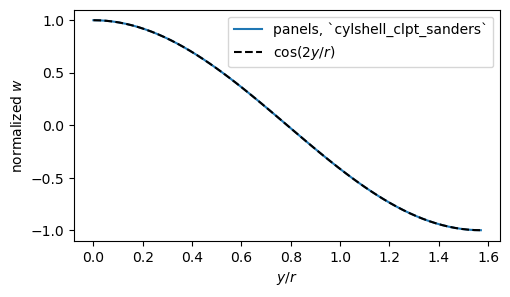

In [4]:
s, mode = ring_mode
ys = np.linspace(0, s.b, 61)
s.uvw(mode, xs=np.full_like(ys, s.a/2), ys=ys)
w = s.fields['w']/np.abs(s.fields['w']).max()
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(ys/s.r, w, label='panels, `cylshell_clpt_sanders`')
ax.plot(ys/s.r, np.cos(2*ys/s.r)*np.sign(w[0]), 'k--', label=r'$\cos(2y/r)$')
ax.set_xlabel('$y/r$')
ax.set_ylabel('normalized $w$')
ax.legend()
plt.show()

### Long sandwich cylinders of Han et al. (2004)

The sandwich cylinders of Han, Kardomateas and Simitses (2004) have faces of boron/epoxy, graphite/epoxy or kevlar/epoxy with the fibres in the hoop direction, $f = 0.1$ in thick, and a core of $c = 1$ in. Their mean radius is $r = (r/h)(2f + c)$ with $r/h$ = 15, 30, 60 and 120. The pressure acts on the outer face, `zp = h/2`, as in the paper, which also gives an elasticity solution. Their shell formulas use the transverse shear stiffness of the core only, Eq. (14a), or that of an effective shear modulus, Eqs. (14b) and (14c). The `cylshell_fsdt_sanders` model is given the same shear stiffness through `fsdt_shear_correction`, `sandwich_ring` of the validation tests. The shell formulas use the hoop modulus $E_f$ of the faces, while panels uses the plane-strain $D_{22}$, which for boron is 0.5% larger and for the other faces less. The formulas also neglect the extensibility of the ring.

In [5]:
rows = []
curves = {}
for face in ['boron', 'graphite', 'kevlar']:
    for kind, col, eq in (('core', 1, 'Eq. (14a)'),
                          ('Gbar', 2, 'Eqs. (14b, 14c)')):
        pcs = []
        for i, ratio in enumerate(val.RATIOS):
            S = val.han_shear_stiffness(face, kind)
            s = val.sandwich_ring(face, ratio, shear=S)
            p_cr, _ = ring_buckling_pressure(s)
            ref = val.HAN2004[face][i][col]
            pcs.append(p_cr)
            rows.append(('%s, $r/h = %d$, shear %s, $p_{cr}$ (Pa)'
                         % (face, ratio, kind), p_cr, ref,
                         'Han et al. (2004), shell formula %s' % eq))
        curves[(face, kind)] = pcs
results_table(rows)

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| boron, $r/h = 15$, shear core, $p_{cr}$ (Pa) | 651374 | 651125 | +3.83e-04 | Han et al. (2004), shell formula Eq. (14a) |
| boron, $r/h = 30$, shear core, $p_{cr}$ (Pa) | 254077 | 253721 | +1.40e-03 | Han et al. (2004), shell formula Eq. (14a) |
| boron, $r/h = 60$, shear core, $p_{cr}$ (Pa) | 67591.7 | 67383 | +3.10e-03 | Han et al. (2004), shell formula Eq. (14a) |
| boron, $r/h = 120$, shear core, $p_{cr}$ (Pa) | 11768.3 | 11717 | +4.38e-03 | Han et al. (2004), shell formula Eq. (14a) |
| boron, $r/h = 15$, shear Gbar, $p_{cr}$ (Pa) | 900244 | 899768 | +5.30e-04 | Han et al. (2004), shell formula Eqs. (14b, 14c) |
| boron, $r/h = 30$, shear Gbar, $p_{cr}$ (Pa) | 323939 | 323361 | +1.79e-03 | Han et al. (2004), shell formula Eqs. (14b, 14c) |
| boron, $r/h = 60$, shear Gbar, $p_{cr}$ (Pa) | 76352.8 | 76087 | +3.49e-03 | Han et al. (2004), shell formula Eqs. (14b, 14c) |
| boron, $r/h = 120$, shear Gbar, $p_{cr}$ (Pa) | 12258.1 | 12203 | +4.51e-03 | Han et al. (2004), shell formula Eqs. (14b, 14c) |
| graphite, $r/h = 15$, shear core, $p_{cr}$ (Pa) | 638083 | 637826 | +4.03e-04 | Han et al. (2004), shell formula Eq. (14a) |
| graphite, $r/h = 30$, shear core, $p_{cr}$ (Pa) | 238580 | 238236 | +1.44e-03 | Han et al. (2004), shell formula Eq. (14a) |
| graphite, $r/h = 60$, shear core, $p_{cr}$ (Pa) | 59383.9 | 59207 | +2.99e-03 | Han et al. (2004), shell formula Eq. (14a) |
| graphite, $r/h = 120$, shear core, $p_{cr}$ (Pa) | 9868.52 | 9829 | +4.02e-03 | Han et al. (2004), shell formula Eq. (14a) |
| graphite, $r/h = 15$, shear Gbar, $p_{cr}$ (Pa) | 875138 | 874654 | +5.53e-04 | Han et al. (2004), shell formula Eqs. (14b, 14c) |
| graphite, $r/h = 30$, shear Gbar, $p_{cr}$ (Pa) | 299183 | 298643 | +1.81e-03 | Han et al. (2004), shell formula Eqs. (14b, 14c) |
| graphite, $r/h = 60$, shear Gbar, $p_{cr}$ (Pa) | 66043.6 | 65825 | +3.32e-03 | Han et al. (2004), shell formula Eqs. (14b, 14c) |
| graphite, $r/h = 120$, shear Gbar, $p_{cr}$ (Pa) | 10210.7 | 10168 | +4.20e-03 | Han et al. (2004), shell formula Eqs. (14b, 14c) |
| kevlar, $r/h = 15$, shear core, $p_{cr}$ (Pa) | 552642 | 551668 | +1.76e-03 | Han et al. (2004), shell formula Eq. (14a) |
| kevlar, $r/h = 30$, shear core, $p_{cr}$ (Pa) | 163172 | 162433 | +4.55e-03 | Han et al. (2004), shell formula Eq. (14a) |
| kevlar, $r/h = 60$, shear core, $p_{cr}$ (Pa) | 30928.2 | 30712 | +7.04e-03 | Han et al. (2004), shell formula Eq. (14a) |
| kevlar, $r/h = 120$, shear core, $p_{cr}$ (Pa) | 4439.04 | 4403 | +8.18e-03 | Han et al. (2004), shell formula Eq. (14a) |
| kevlar, $r/h = 15$, shear Gbar, $p_{cr}$ (Pa) | 721516 | 719856 | +2.31e-03 | Han et al. (2004), shell formula Eqs. (14b, 14c) |
| kevlar, $r/h = 30$, shear Gbar, $p_{cr}$ (Pa) | 189342 | 188347 | +5.28e-03 | Han et al. (2004), shell formula Eqs. (14b, 14c) |
| kevlar, $r/h = 60$, shear Gbar, $p_{cr}$ (Pa) | 32638.2 | 32397 | +7.45e-03 | Han et al. (2004), shell formula Eqs. (14b, 14c) |
| kevlar, $r/h = 120$, shear Gbar, $p_{cr}$ (Pa) | 4506.82 | 4470 | +8.24e-03 | Han et al. (2004), shell formula Eqs. (14b, 14c) |

The critical pressures against $r/h$, with the shell formulas (markers) and the elasticity solution of Han et al. (2004) (crosses):

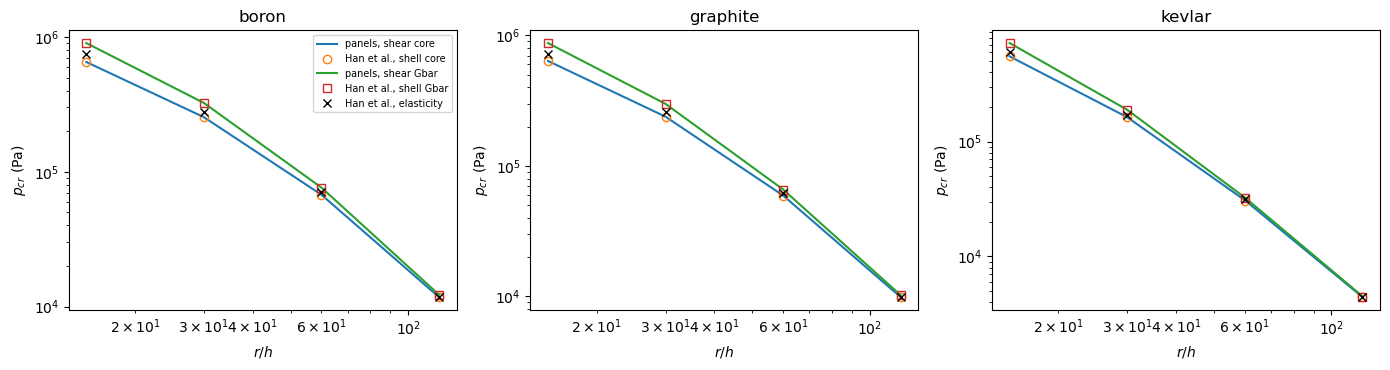

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, face in zip(axes, ['boron', 'graphite', 'kevlar']):
    data = np.array(val.HAN2004[face])
    for kind, col, style in (('core', 1, 'o'), ('Gbar', 2, 's')):
        ax.loglog(val.RATIOS, curves[(face, kind)], '-',
                  label='panels, shear %s' % kind)
        ax.loglog(val.RATIOS, data[:, col], style, mfc='none',
                  label='Han et al., shell %s' % kind)
    ax.loglog(val.RATIOS, data[:, 0], 'kx', label='Han et al., elasticity')
    ax.set_title(face)
    ax.set_xlabel('$r/h$')
    ax.set_ylabel('$p_{cr}$ (Pa)')
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## Non-linear analyses

The callables of the `Shell` are passed directly to `structsolve.Analysis`. It passes its load factor to the callables that accept `inc`, and uses `calc_fext(inc=1., c=c)` as the load vector of the current configuration in the arc-length methods.

The panel of $0.3 \times 0.2$ m, a plate or a cylindrical shell of $r = 0.4$ m, has the unsymmetric and unbalanced laminate $[30/-45/0/90]$. Its edges have $w = 0$ and the in-plane rigid-body motions removed. It is loaded by a uniform follower pressure, `follower='quadratic'`, plus a sinusoidal follower pressure on a strip, `follower='linear'`; see `Shell.add_pressure_load` for the two truncations of the area vector. The Newton-Raphson iterations of `structsolve.Analysis` converge quadratically, because the tangent stiffness matrix includes the exact load stiffness. The residual of each iteration is recorded by wrapping `calc_fint`.

In [7]:
def make_shell(model):
    E11 = 142.5e9
    E22 = E11/20
    s = Shell(model=model, a=0.3, b=0.2, m=5, n=5, plyt=0.125e-3,
              stack=[30, -45, 0, 90],
              laminaprop=(E11, E22, 0.25, 0.5*E22, 0.5*E22, 0.5*E22),
              r=0.4 if model.startswith('cylshell') else None)
    s.nx = s.ny = 8
    for edge in ('x1', 'x2', 'y1', 'y2'):
        for field in 'uvw':
            setattr(s, edge + field, 0. if field == 'w' else 1.)
            setattr(s, edge + field + 'r', 1.)
    s.x1u = 0.
    s.y1v = 0.
    return s


def follower_shell(model):
    s = make_shell(model)
    s.add_pressure_load(-8.e3 if model.startswith('cyl') else 1.5e3,
                        follower='quadratic', cte=False)
    s.add_pressure_load(lambda x, y: 2.e3*np.sin(np.pi*x/s.a),
                        y1=0.05, y2=0.15, follower='linear', cte=False)
    return s


histories = {}
rows = []
for model in ['plate_clpt_donnell', 'cylshell_clpt_sanders',
              'cylshell_fsdt_sanders']:
    s = follower_shell(model)
    fext = s.calc_fext()
    calls = []

    def calc_fint(c, inc=1., silent=True, s=s, fext=fext, calls=calls):
        fint = s.calc_fint(c, inc=inc)
        ref = max(np.linalg.norm(inc*fext), np.linalg.norm(fint))
        calls.append((len(an.increments), np.linalg.norm(fint - inc*fext)/ref))
        return fint

    an = Analysis(s.calc_fext, calc_fint, s.calc_kC, s.calc_kG)
    an.initialInc = 0.25
    an.relTOL = 1.e-12
    an.maxNumIter = 20
    an.static(NLgeom=True, silent=True)
    c = an.cs[-1]
    h = len(s.stack)*s.plyt
    wmax = np.abs(s.uvw(c, gridx=9, gridy=9)[1]['w']).max()
    histories[model] = calls
    # the same pressures as dead loads
    s_dead = make_shell(model)
    for load in s.pressure_loads_inc:
        s_dead.pressure_loads_inc.append(load[:5])
    an_dead = Analysis(s_dead.calc_fext, s_dead.calc_fint, s_dead.calc_kC,
                       s_dead.calc_kG)
    an_dead.initialInc = 0.25
    an_dead.static(NLgeom=True, silent=True)
    wdead = np.abs(s_dead.uvw(an_dead.cs[-1], gridx=9, gridy=9)[1]['w']).max()
    print('%-22s load factors %s, max |w|/h: follower %.3f, dead %.3f'
          % (model, np.round(an.increments, 3), wmax/h, wdead/h))

plate_clpt_donnell     load factors [0.25  0.528 0.836 1.   ], max |w|/h: follower 8.230, dead 8.234


cylshell_clpt_sanders  load factors [0.25  0.528 0.836 1.   ], max |w|/h: follower 4.872, dead 4.851


cylshell_fsdt_sanders  load factors [0.25  0.528 0.836 1.   ], max |w|/h: follower 4.873, dead 4.852


The residual of each iteration, per load step, for the plate: once small, it is roughly squared at each iteration.

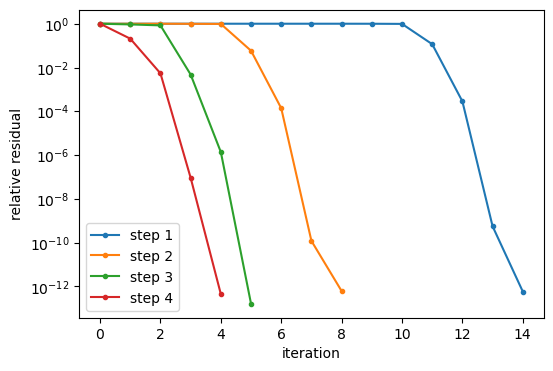

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
calls = histories['plate_clpt_donnell']
for step in sorted(set(st for st, e in calls)):
    errors = [e for st, e in calls if st == step]
    ax.semilogy(errors, 'o-', ms=3, label='step %d' % (step + 1))
ax.set_xlabel('iteration')
ax.set_ylabel('relative residual')
ax.legend()
plt.show()

## Linear static analysis and kinetic criterion

A geometrically linear structure under a follower load solves the unsymmetric system $(\boldsymbol{K}_C + \boldsymbol{K}_{C,follower})\boldsymbol{c} = \boldsymbol{F}_{ext}$. `structsolve.Analysis` does this with `static(NLgeom=False)`, since `Shell.calc_fext` accepts the configuration `c`. The result is compared with the direct solution of that system and with the dead load solution $\boldsymbol{K}_C\boldsymbol{c} = \boldsymbol{F}_{ext}$.

In [9]:
rows = []
for model in ['plate_clpt_donnell', 'cylshell_fsdt_sanders']:
    s = make_shell(model)
    s.add_pressure_load(-2.e5, follower=True, cte=False)
    s.add_pressure_load(lambda x, y: 1.e5*(1 + x/s.a), x1=0.1, follower=True,
                        cte=False)
    an = Analysis(s.calc_fext, s.calc_fint, s.calc_kC, s.calc_kG)
    an.relTOL = 1.e-12
    increments, cs = an.static(NLgeom=False, silent=True)
    k0 = s.calc_kC()
    direct = static(k0 + s.calc_kCfollower(), s.calc_fext(), silent=True)[1][0]
    c_dead = solve(k0, s.calc_fext(), silent=True)
    wmax = lambda c: np.abs(s.uvw(c, gridx=9, gridy=9)[1]['w']).max()
    print('%-22s max |w|: Analysis %.6e m, direct %.6e m, dead load %.6e m'
          % (model, wmax(cs[0]), wmax(direct), wmax(c_dead)))
    rows.append(('`%s`, largest deflection (m)' % model, wmax(cs[0]), wmax(direct),
                 'direct solution of $(\\boldsymbol{K}_C + \\boldsymbol{K}_{C,follower})\\boldsymbol{c} = \\boldsymbol{F}_{ext}$'))
results_table(rows)

plate_clpt_donnell     max |w|: Analysis 2.595991e+00 m, direct 2.595991e+00 m, dead load 2.472634e+00 m
cylshell_fsdt_sanders  max |w|: Analysis 2.353146e-02 m, direct 2.353146e-02 m, dead load 2.248759e-02 m


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, largest deflection (m) | 2.59599 | 2.59599 | -5.17e-13 | direct solution of $(\boldsymbol{K}_C + \boldsymbol{K}_{C,follower})\boldsymbol{c} = \boldsymbol{F}_{ext}$ |
| `cylshell_fsdt_sanders`, largest deflection (m) | 0.0235315 | 0.0235315 | +4.73e-12 | direct solution of $(\boldsymbol{K}_C + \boldsymbol{K}_{C,follower})\boldsymbol{c} = \boldsymbol{F}_{ext}$ |

Non-conservative systems may lose stability by flutter, which only the kinetic criterion detects. `structsolve.freq` solves the unsymmetric eigenvalue problem of the stiffness matrix with the load stiffness at a fraction of the critical load. A flutter load would make the eigenvalues complex.

The cantilever cylinder of Schweizerhof and Ramm (1984), boundary condition B1, is $L = 6r$ long with $r = 100$ and $h = 1$. It is modelled by a sector of $\pi r/3$ for the mode with three circumferential waves. It diverges instead: its lowest $\omega^2$ stays real and vanishes at the critical load of the static criterion.

critical pressure of the static criterion: 1.862157
p/p_cr = 0.00: lowest omega^2 = 1.714490e+07 -4.0e-46j
p/p_cr = 0.25: lowest omega^2 = 1.285870e+07 +2.1e-15j
p/p_cr = 0.50: lowest omega^2 = 8.572485e+06 +9.0e-52j
p/p_cr = 0.75: lowest omega^2 = 4.286252e+06 +5.1e-61j
p/p_cr = 0.90: lowest omega^2 = 1.714503e+06 -0.0e+00j
p/p_cr = 1.00: lowest omega^2 = 0.000000e+00 -0.0e+00j


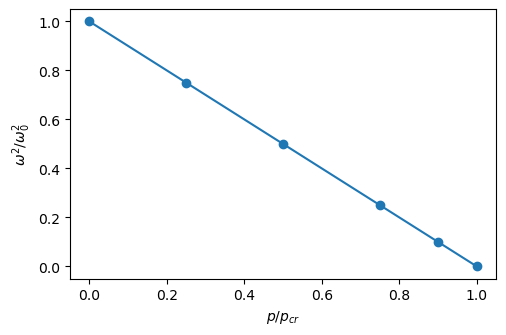

In [10]:
s = val.schweizerhof_sector(600., 100., 1., 3, 'B1')
s.rho = 7.8e-9
s.add_pressure_load(-1., cte=False, follower=True)
k0 = s.calc_kC()
c0 = solve(k0, s.calc_fext(), silent=True)
KL = s.calc_kG(c=c0) + s.calc_kCfollower()
lam_cr = np.real(lb(k0, KL, silent=True, num_eigvalues=4)[0][0])
kM = s.calc_kM()
fracs = np.array([0., 0.25, 0.5, 0.75, 0.9, 1.])
w2 = []
for frac in fracs:
    lambda2 = freq(k0 + frac*lam_cr*KL, kM, silent=True, sparse_solver=False,
                   sort=False)[0]
    finite = lambda2[np.isfinite(lambda2)]
    w2.append(-finite[np.argmin(np.abs(finite))])
w2 = np.array(w2)
print('critical pressure of the static criterion: %.6f' % lam_cr)
for frac, w in zip(fracs, w2):
    print('p/p_cr = %.2f: lowest omega^2 = %.6e %+.1ej' % (frac, w.real, w.imag))
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(fracs, w2.real/w2[0].real, 'o-')
ax.set_xlabel('$p/p_{cr}$')
ax.set_ylabel(r'$\omega^2/\omega_0^2$')
plt.show()

## Validation notebooks

The comparisons with the literature are reproduced, per reference, by these notebooks. They use the models and the data of `tests/tests_shell/test_follower_pressure_validation.py`:

- [han2004_sandwich_rings.ipynb](han2004_sandwich_rings.ipynb): long sandwich cylinders, Tables 2-4 of Han et al. (2004);
- [kardomateas2003_sandwich_rings.ipynb](kardomateas2003_sandwich_rings.ipynb): Tables 2-4 of Kardomateas and Simitses (2003);
- [kardomateas1993_thick_rings.ipynb](kardomateas1993_thick_rings.ipynb): thick orthotropic and isotropic rings, Tables 1 and 2 and Figs. 2 and 5 of Kardomateas (1993);
- [schweizerhof1984_pressure_loads.ipynb](schweizerhof1984_pressure_loads.ipynb): Tables 2-4 and Fig. 13 of Schweizerhof and Ramm (1984), rings and cantilever cylinders with an unsymmetric load stiffness;
- [nasa_sp8007_external_pressure.ipynb](nasa_sp8007_external_pressure.ipynb): Batdorf's equations for lateral and hydrostatic pressure of NASA SP-8007 (2020).

## References

1. D. O. Brush and B. O. Almroth, "Buckling of Bars, Plates, and Shells". McGraw-Hill, New York, 1975.
2. J.-H. Han, G. A. Kardomateas and G. J. Simitses, "Elasticity, shell theory and finite element results for the buckling of long sandwich cylindrical shells under external pressure". Composites Part B: Engineering, 35:591-598, 2004. https://doi.org/10.1016/j.compositesb.2003.07.002.
3. H. D. Hibbitt, "Some follower forces and load stiffness". International Journal for Numerical Methods in Engineering, 14(6):937-941, 1979.
4. G. A. Kardomateas, "Buckling of thick orthotropic cylindrical shells under external pressure". Journal of Applied Mechanics, 60(1):195-202, 1993. https://doi.org/10.1115/1.2900745.
5. G. A. Kardomateas and G. J. Simitses, "Buckling of long sandwich cylindrical shells under external pressure". In: E. E. Gdoutos and Z. P. Marioli-Riga (eds), Recent Advances in Composite Materials, pp. 291-300, Kluwer Academic Publishers (Springer), Dordrecht, 2003. https://doi.org/10.1007/978-94-017-2852-2_24.
6. NASA, "Buckling of thin-walled circular cylinders". NASA/SP-8007-2020/REV 2, NASA Langley Research Center, 2020. https://ntrs.nasa.gov/citations/20205011530.
7. A. Pflüger, "Stabilitätsprobleme der Elastostatik". 3rd ed., Springer-Verlag, Berlin, Heidelberg, New York, 1975. https://doi.org/10.1007/978-3-662-09994-0.
8. K. Schweizerhof and E. Ramm, "Displacement dependent pressure loads in nonlinear finite element analyses". Computers & Structures, 18(6):1099-1114, 1984. https://doi.org/10.1016/0045-7949(84)90154-8.
9. S. P. Timoshenko and J. M. Gere, "Theory of Elastic Stability". 2nd ed., McGraw-Hill, New York, 1961.